# Ejemplo con Python

Para comprender mejor cómo funciona el Análisis de Componentes Principales (PCA) en la práctica, consideremos un ejemplo concreto que involucra las notas de 120 alumnos en siete asignaturas diferentes: Matemáticas, Física, Lengua, Inglés, Historia, Literatura y Economía. Lo que crea un conjunto de datos multidimensional. Estas notas pueden mostrar diversas relaciones de correlación entre sí. Nuestro objetivo es utilizar el PCA para simplificar esta información compleja y obtener una visión más clara de las tendencias subyacentes en el desempeño académico de los estudiantes.

A medida que avanzamos en este ejemplo, exploraremos paso a paso cómo aplicar el PCA a estos datos utilizando Python, desde la selección del número adecuado de componentes principales hasta la interpretación de los resultados. A lo largo del proceso, veremos cómo el PCA nos permite reducir la dimensionalidad de nuestros datos y facilitar la toma de decisiones informadas en el entorno educativo.


El fichero con el que vamos a trabajar se llama "NOTAS.xlsx" y lo podeis encontrar en la carpeta "Datos".

## Preparación del entorno

Lo primero que vamos a necesitar para empezar a trabajar, es tener todas las librerías necesarias cargadas en el entorno "prompt" de Anaconda, mediante el código "pip install nombre\_librería".

Una vez están cargadas las librerías en el sistema, debemos llamarlas en nuestro script. A continuación se muestran todas las librerías utilizadas para realizar un PCA completo junto con una breve descripción de su utilidad.

In [1]:
import os # Proporciona funciones para interactuar con el sistema operativo.
import pandas as pd # Manipulación y análisis de datos tabulares (filas y columnas).
import numpy as np # Operaciones numéricas y matriciales.
import seaborn as sns # Visualización estadística de datos.
import matplotlib.pyplot as plt # Creación de gráficos y visualizaciones.

# Matplotlib es una herramienta versátil para crear gráficos desde cero,
# mientras que Seaborn simplifica la creación de gráficos estadísticos.

from sklearn.decomposition import PCA # Implementación del Análisis de Componentes Principales (PCA).
from sklearn.preprocessing import StandardScaler # Estandarización de datos para análisis estadísticos.

Definimos nuestro entorno de trabajo utilizando la función "chdir" de la librería "os".

In [2]:
os.chdir('G:\Mi unidad\Titulo Propio 1\M2\Datos') 

## Lectura de datos

Una vez cargadas las librerías y definido el entorno de trabajo, procedemos a la lectura en formato DataFrame de la base de datos, la cual, esta en formato tabla o tabulado. Para ello hacemos uso de la función $read\_excel$ de la librería $pandas$. Le asignamos el nombre de $notas$. Indicamos que la primera variable ($Alumno$) es el índice del DataFrame y posteriormente eliminamos dicha variable junto con la última ($EXTRA\_ESC$). Quedándonos así únicamente con las variables numéricas objeto del PCA.

In [3]:

# Cargar un archivo Excel llamado 'notas.xlsx' en un DataFrame llamado notas.
notas = pd.read_excel('NOTAS.xlsx') 

# Establecer la columna 'Alumno' como índice del DataFrame notas y eliminarla.
notas = notas.set_index('Alumno', drop=True)
notas
 

,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia,EXTRA_ESC
Alumno,,,,,,,,
1,8.207234,6.575511,6.495721,7.417732,9.268846,8.035363,5.803576,Musi-Dep
2,5.370086,3.933386,6.039864,6.071163,6.191998,7.316149,4.321895,Deporte
3,4.383578,2.992181,6.425888,6.246812,5.397638,6.741643,6.237044,Deporte
4,7.637691,5.812467,8.017976,8.071904,7.278631,9.028017,6.335278,Musi-Dep
5,5.385788,5.759898,5.211448,5.684005,5.444812,5.775183,6.474425,Deporte
...,...,...,...,...,...,...,...,...
116,6.273739,5.199807,7.159702,8.320098,8.052360,8.271367,3.620958,Música
117,6.603260,4.876323,5.256840,5.763320,6.164681,5.889371,6.822079,Música
118,5.242693,3.861662,6.638740,5.333194,6.154258,6.244144,4.678243,Deporte


In [4]:
# Guarda la variable'EXTRA_ESC' en un dataframe
extra = notas.iloc[:, [7]]
extra


,EXTRA_ESC
Alumno,
1,Musi-Dep
2,Deporte
3,Deporte
4,Musi-Dep
5,Deporte
...,...
116,Música
117,Música
118,Deporte


In [5]:
#Elimina la variable 'EXTRA_ESC' del DataFrame 'notas'.
eliminar = ['EXTRA_ESC']
notas = notas.drop(eliminar, axis=1)
notas


,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia
Alumno,,,,,,,
1,8.207234,6.575511,6.495721,7.417732,9.268846,8.035363,5.803576
2,5.370086,3.933386,6.039864,6.071163,6.191998,7.316149,4.321895
3,4.383578,2.992181,6.425888,6.246812,5.397638,6.741643,6.237044
4,7.637691,5.812467,8.017976,8.071904,7.278631,9.028017,6.335278
5,5.385788,5.759898,5.211448,5.684005,5.444812,5.775183,6.474425
...,...,...,...,...,...,...,...
116,6.273739,5.199807,7.159702,8.320098,8.052360,8.271367,3.620958
117,6.603260,4.876323,5.256840,5.763320,6.164681,5.889371,6.822079
118,5.242693,3.861662,6.638740,5.333194,6.154258,6.244144,4.678243


In [6]:
# Genera una lista con los nombres de las variables.
variables = list(notas.columns)  
variables

['Matematicas',
 'Fisica',
 'Lengua',
 'Ingles',
 'Historia',
 'Literatura',
 'Economia']

## Analisis desciptivo

Antes de empezar con el PCA es conveniente realizar un análisis descriptivo de las variables, para observar si hay alguna anomalía en los datos, como datos fuera de rango, atípicos o perdidos.

In [7]:
# Cálculo de los estadísticos descriptivos.

# Calcula las estadísticas descriptivas para cada variable y crea un DataFrame con los resultados.
estadisticos = pd.DataFrame({
    'Mínimo': notas[variables].min(),
    'Percentil 25': notas[variables].quantile(0.25),
    'Mediana': notas[variables].median(),
    'Percentil 75': notas[variables].quantile(0.75),
    'Media': notas[variables].mean(),
    'Máximo': notas[variables].max(),
    'Desviación Estándar': notas[variables].std(),
    'Varianza': notas[variables].var(),
    'Datos Perdidos': notas[variables].isna().sum()  # Cuenta los valores NaN por variable.
})

estadisticos

,Mínimo,Percentil 25,Mediana,Percentil 75,Media,Máximo,Desviación Estándar,Varianza,Datos Perdidos
Matematicas,1.655882,4.330866,5.266349,6.236496,5.302194,8.856182,1.469790,2.160281,0
Fisica,0.211836,3.554006,4.509948,5.643187,4.631731,8.371603,1.515356,2.296303,0
Lengua,2.965868,5.144678,6.048062,6.625050,5.971550,8.571286,1.274833,1.625199,0
Ingles,3.271631,5.773388,6.748701,8.038959,6.806254,10.623887,1.473230,2.170406,0
Historia,2.326892,5.551465,6.268428,7.131080,6.354733,9.412083,1.373226,1.885749,0
Literatura,2.402896,5.611092,6.585991,7.549098,6.614774,10.456179,1.456607,2.121703,0
Economia,1.640227,4.045458,5.079972,6.144807,5.120498,8.779209,1.507727,2.273239,0


Los datos muestran una pequeña anomalía, el máximo de las notas en Ingles y literatura superan el 10, procedemos a convertir estos valores en el valor máximo (solo hay tres), presuponiendo que es este el valor correcto. Salvo esto, la base de datos parece correcta, sin datos perdidos ni valores atípicos (media próxima a la mediana).

In [8]:
# Filtra las observaciones que tienen una puntuación mayor a 10 en las variables de lengua o inglés.
observaciones_altas = notas[(notas['Ingles'] > 10) | (notas['Literatura'] > 10)]

# Cuenta cuántas observaciones cumplen con el criterio de tener una puntuación mayor a 10 en lengua o inglés.
cantidad_observaciones_altas = len(observaciones_altas)
cantidad_observaciones_altas



3

In [9]:
# Ajusta las observaciones que tienen una puntuación mayor a 10 en las variables de lengua o inglés a 10.
notas['Ingles'] = notas['Ingles'].clip(upper=10)
notas['Literatura'] = notas['Literatura'].clip(upper=10)

También es importante analizar las relaciones entre las variables, ya que si están mostrasen fuerte independencia, no tendría sentido realizar un PCA. Para ello calculamos las matrices de covarianzas y correlaciones.

In [10]:
# Calcular la matriz de covarianzas
C = notas.cov()
C


,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia
Matematicas,2.160281,1.620503,-0.132365,1.031410,0.255448,0.187213,1.254330
Fisica,1.620503,2.296303,-0.133335,0.861911,0.338163,0.146459,0.763320
Lengua,-0.132365,-0.133335,1.625199,0.875380,1.252322,1.185402,-0.766859
Ingles,1.031410,0.861911,0.875380,2.133620,0.932079,0.732922,0.067990
Historia,0.255448,0.338163,1.252322,0.932079,1.885749,1.450936,-0.908800
Literatura,0.187213,0.146459,1.185402,0.732922,1.450936,2.091323,-0.601950
Economia,1.254330,0.763320,-0.766859,0.067990,-0.908800,-0.601950,2.273239


In [11]:
# Calcula y representación de la matriz de correlación entre las 
# variables del DataFrame 'notas'.
R = notas.corr()
R


,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia
Matematicas,1.000000,0.727579,-0.070642,0.480416,0.126563,0.088079,0.566023
Fisica,0.727579,1.000000,-0.069020,0.389394,0.162506,0.066833,0.334095
Lengua,-0.070642,-0.069020,1.000000,0.470094,0.715354,0.642987,-0.398970
Ingles,0.480416,0.389394,0.470094,1.000000,0.464678,0.346968,0.030872
Historia,0.126563,0.162506,0.715354,0.464678,1.000000,0.730627,-0.438939
Literatura,0.088079,0.066833,0.642987,0.346968,0.730627,1.000000,-0.276075
Economia,0.566023,0.334095,-0.398970,0.030872,-0.438939,-0.276075,1.000000


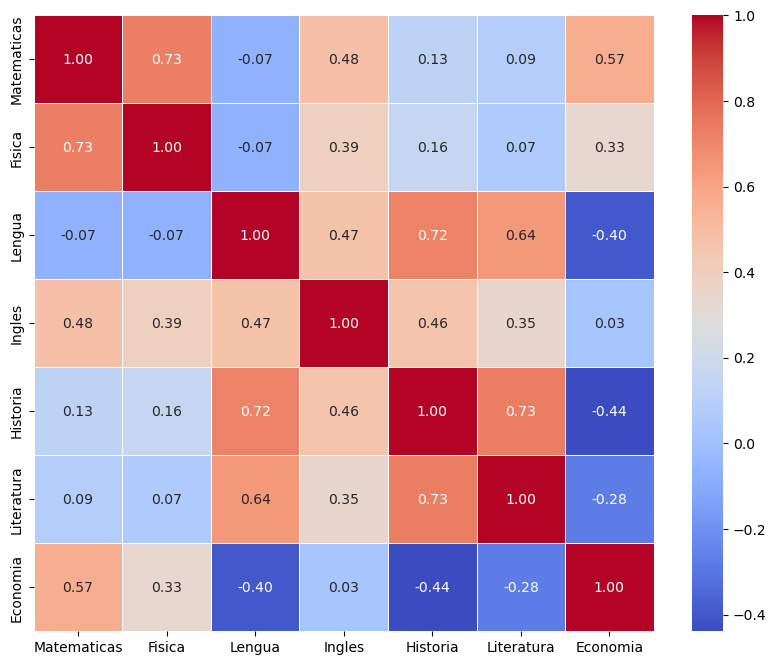

In [12]:
# Crea una nueva figura de tamaño 10x8 pulgadas para el gráfico.
plt.figure(figsize=(10, 8))

# Genera un mapa de calor (heatmap) de la matriz de correlación 'R' utilizando Seaborn.
# 'annot=True' agrega los valores de correlación en las celdas.
# 'cmap' establece el esquema de colores (en este caso, 'coolwarm' para colores fríos y cálidos).
# 'fmt' controla el formato de los números en las celdas ('.2f' para dos decimales).
# 'linewidths' establece el ancho de las líneas que separan las celdas.
sns.heatmap(R, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
# Muestra el gráfico.
plt.show()

Observemos que las variables con mayor correlación positiva son Lengua e Historia, Matemáticas y Física y también Historia y Literatura. Por otro lado, se observa una destacable correlación negativa entre las notas de Economía  con las asignaturas de  Lengua e Historia.



## Análisis de Componentes Principales (PCA)

Ahora si, una vez cargados y validado los datos, y observado las dependencias entre las variables, estamos en disposición de empezar el PCA. Para ello, lo primero, estandarizamos los datos, que pese a estar en la misma escala y no ser imprescindible para realizar el análisis, siempre es aconsejable.

### Estandarización de los datos

In [13]:
# -------------------------------- Analisis PCA:
    
# Estandarizamos los datos:
# Utilizamos StandardScaler() para estandarizar (normalizar) las variables.
# - StandardScaler calcula la media y la desviación estándar de las variables en 'notas' durante el ajuste.
# - Luego, utiliza estos valores para transformar 'notas' de manera que tengan media 0 y desviación estándar 1.
# - El método fit_transform() realiza ambas etapas de ajuste y transformación en una sola llamada.
# Finalmente, convertimos la salida en un DataFrame usando pd.DataFrame().
notas_estandarizadas = pd.DataFrame(
    StandardScaler().fit_transform(notas),  # Datos estandarizados
    columns=['{}_z'.format(variable) for variable in variables],  # Nombres de columnas estandarizadas
    index=notas.index  # Índices (etiquetas de filas) del DataFrame
)

notas_estandarizadas

,Matematicas_z,Fisica_z,Lengua_z,Ingles_z,Historia_z,Literatura_z,Economia_z
Alumno,,,,,,,
1,1.984788,1.288100,0.412892,0.423952,2.130991,0.989359,0.454951
2,0.046385,-0.462778,0.053811,-0.501785,-0.119002,0.489940,-0.531895
3,-0.627619,-1.086494,0.357885,-0.381030,-0.699891,0.091006,0.743655
4,1.595663,0.782447,1.611981,0.873680,0.675615,1.678652,0.809081
5,0.057113,0.747611,-0.598737,-0.767947,-0.665394,-0.580099,0.901758
...,...,...,...,...,...,...,...
116,0.663781,0.376451,0.935914,1.044308,1.241417,1.153238,-0.998740
117,0.888917,0.162086,-0.562981,-0.713420,-0.138979,-0.500808,1.133306
118,-0.040653,-0.510308,0.525549,-1.009122,-0.146600,-0.254455,-0.294556


### Aplicamos sentencia PCA (scikit-learn)

In [14]:
# Crea una instancia de Análisis de Componentes Principales (ACP):
# - Utilizamos PCA(n_components=7) para crear un objeto PCA que realizará un análisis de componentes principales.
# - Establecemos n_components en 7 para retener el maximo de las componentes principales (maximo= numero de variables).
pca = PCA(n_components=7)

# Aplicar el Análisis de Componentes Principales (ACP) a los datos estandarizados:
# - Usamos pca.fit(notas_estandarizadas) para ajustar el modelo de ACP a los datos estandarizados.
fit = pca.fit(notas_estandarizadas)


A continuación, procedemos a calcular los autovalores asociados a las componentes principales (valores $\lambda$ que resuelven la ecuación $\text{det}(\Sigma - \lambda I) = 0$).

In [15]:

# Obtener los autovalores asociados a cada componente principal.
autovalores = fit.explained_variance_
autovalores


array([2.94379179, 2.34673158, 0.57223969, 0.55789592, 0.27018714,
       0.22101723, 0.14696017])

In [16]:
autovalores[0]/sum(autovalores)

0.4170371704041769

In [17]:
autovalores[1]/sum(autovalores)

0.33245364104468256

Una vez tenemos calculados los autovalores, procedemos a calculas sus autovectores asociados

In [18]:
# Obtener los autovectores asociados a cada componente principal y transponerlos.
autovectores = pd.DataFrame(pca.components_.T, 
                            columns = ['Autovector {}'.format(i) for i in range(1, fit.n_components_+1)],
                            index = ['{}_z'.format(variable) for variable in variables])
autovectores

,Autovector 1,Autovector 2,Autovector 3,Autovector 4,Autovector 5,Autovector 6,Autovector 7
Matematicas_z,-0.116240,-0.603271,-0.033999,0.100053,0.115015,0.476871,-0.608893
Fisica_z,-0.126881,-0.535755,-0.586239,-0.164591,-0.328375,-0.441445,0.152962
Lengua_z,-0.495842,0.161451,0.349809,-0.002797,-0.720495,-0.079181,-0.283403
Ingles_z,-0.389297,-0.293196,0.478910,-0.561167,0.390921,-0.190845,0.170232
Historia_z,-0.534486,0.055412,-0.253115,0.072586,-0.019120,0.595339,0.535840
Literatura_z,-0.483113,0.064762,-0.070052,0.631355,0.404679,-0.424938,-0.120641
Economia_z,0.232175,-0.479308,0.484223,0.494069,-0.207069,-0.005291,0.441449


Con los autovectores formamos la matriz de transformación, a traves de la cual, conseguimos las coordenadas de cada observación en las nuevas variables / componentes / ejes.

In [19]:
# Construimos las componentes
resultados_pca = pd.DataFrame(fit.transform(notas_estandarizadas), 
                              columns=['Componente {}'.format(i) for i in range(1, fit.n_components_+1)],
                              index=notas_estandarizadas.index)
resultados_pca

,Componente 1,Componente 2,Componente 3,Componente 4,Componente 5,Componente 6,Componente 7
Alumno,,,,,,,
1,-2.275246,-1.981018,-0.863543,0.751606,-0.061033,1.110100,0.167012
2,-0.074596,0.655838,-0.213520,0.400140,0.233054,0.041687,-0.557378
3,0.684463,0.740888,1.131868,0.702924,-0.225993,-0.234565,-0.008051
4,-2.408402,-1.619371,0.572520,1.044686,-0.394434,-0.194241,-0.643340
5,1.339605,-0.813157,-0.371732,0.346270,-0.516506,-0.263227,0.230054
...,...,...,...,...,...,...,...
116,-2.448080,-0.135030,-0.294358,-0.259431,0.336412,0.131243,-0.348875
117,1.012343,-1.088155,-0.044811,0.697841,-0.258934,0.657152,0.007886
118,0.334631,0.795226,-0.086591,0.327917,-0.649422,0.379269,-0.551919


### Determinar el número de Componentes Principales

Hemos desarrollado el PCA completo, con todas las posibles Componentes, no obstante, como sabemos, este no será el trabajo habitual, pues nuestro objetivo será reducir la dimensionalidad. Para ello debemos decidir con cuantas CP nos vamos a quedar. Para ello, procedemos a calcular la varianza explicada / varianza explicada acumulada y lel gráfico del "Codo".

In [20]:
# Obtener la varianza explicada por cada componente principal como un porcentaje de la varianza total.
var_explicada = fit.explained_variance_ratio_*100

# Calcular la varianza explicada acumulada a medida que se agregan cada componente principal.
var_acumulada = np.cumsum(var_explicada)

# Crear un DataFrame de pandas con los datos anteriores y establecer índice.
data = {'Autovalores': autovalores, 'Variabilidad Explicada': var_explicada, 'Variabilidad Acumulada': var_acumulada}
tabla = pd.DataFrame(data, index=['Componente {}'.format(i) for i in range(1, fit.n_components_+1)]) 

# Imprimir la tabla
print(tabla)



              Autovalores  Variabilidad Explicada  Variabilidad Acumulada
Componente 1     2.943792               41.703717               41.703717
Componente 2     2.346732               33.245364               74.949081
Componente 3     0.572240                8.106729               83.055810
Componente 4     0.557896                7.903526               90.959336
Componente 5     0.270187                3.827651               94.786987
Componente 6     0.221017                3.131077               97.918064
Componente 7     0.146960                2.081936              100.000000


Como podemos observar en la tabla anterior, usando las dos primeras componentes conseguiremos explicar el $74.9\%$ de la variabilidad total de las variables originales. La decisión de cuántas componentes seleccionar es subjetiva y se debe decidir teniendo en cuenta dos factores, por un lado, la cantidad de variabilidad que deseamos explicar y por otro, la dimensión que queremos conseguir. En este ejemplo, consideramos que añadiendo una tercera componente no se consigue $demasiado$ beneficio en cuanto a la cantidad de variabilidad explicada. No obstante, esta decisión podría ser diferente, si por ejemplo, quisiéramos explicar un mínimo superior de variabilidad.

Realizamos la representación de la variabilidad explicada (gráfico del 'codo'), para observar gráficamente como esta se estabiliza una vez seleccionadas las dos primeras componentes.

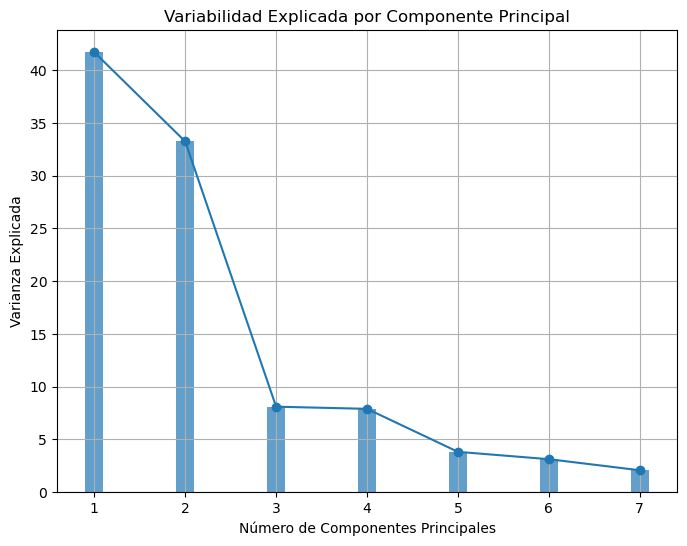

In [21]:

# Representacion de la variabilidad explicada (Método del codo):   

def plot_varianza_explicada(var_explicada, n_components):
    """
    Representa la variabilidad explicada por cada componente principal
    Args:
      var_explicada (array): Un array que contiene el porcentaje de varianza explicada
        por cada componente principal. Generalmente calculado como
        var_explicada = fit.explained_variance_ratio_ * 100.
      n_components (int): El número total de componentes principales.
        Generalmente calculado como fit.n_components.
    """  
    # Crear un rango de números de componentes principales de 1 a n_components
    num_componentes_range = np.arange(1, n_components + 1)

    # Crear una figura de tamaño 8x6
    plt.figure(figsize=(8, 6))

    # Trazar la varianza explicada en función del número de componentes principales
    plt.plot(num_componentes_range, var_explicada, marker='o')

    # Etiquetas de los ejes x e y
    plt.xlabel('Número de Componentes Principales')
    plt.ylabel('Varianza Explicada')

    # Título del gráfico
    plt.title('Variabilidad Explicada por Componente Principal')

    # Establecer las marcas en el eje x para que coincidan con el número de componentes
    plt.xticks(num_componentes_range)

    # Mostrar una cuadrícula en el gráfico
    plt.grid(True)

    # Agregar barras debajo de cada punto para representar el porcentaje de variabilidad explicada
    # - 'width': Ancho de las barras de la barra. En este caso, se establece en 0.2 unidades.
    # - 'align': Alineación de las barras con respecto a los puntos en el eje x. 
    #   'center' significa que las barras estarán centradas debajo de los puntos.
    # - 'alpha': Transparencia de las barras. Un valor de 0.7 significa que las barras son 70% transparentes.
    plt.bar(num_componentes_range, var_explicada, width=0.2, align='center', alpha=0.7)

    # Mostrar el gráfico
    plt.show()
    
plot_varianza_explicada(var_explicada, fit.n_components_)


Podemos observar que la variabilidad explicada por cada componente, decae y se estabiliza a partir de la tercera. Por lo tanto, optamos por retener únicamente dos de las siete componentes principales, las cuales explican conjuntamente el $74.91\%$ de la varianza de las variables originales. Los dos autovalores correspondientes a estas componentes seleccionadas son $2.94$ y $2.35$, representando el $41.7\%$ y el $33.3\%$ de la variabilidad, respectivamente.

Una vez hemos decidido quedarnos con las dos primeras componentes, procedemos a calcularlas. Para ello necesitamos conocer la matriz de transformación formada por los autovectores o vectores propios asociados a los autovalores seleccionados. Repetimos el proceso seleccionando unicamente dos componentes principales


In [22]:
# Crea una instancia de ACP con las dos primeras componentes que nos interesan y aplicar a los datos.
pca = PCA(n_components=2)
fit = pca.fit(notas_estandarizadas)

# Obtener los autovalores asociados a cada componente principal.
autovalores = fit.explained_variance_

# Obtener los autovectores asociados a cada componente principal y transponerlos.
# Transponemos los autovectores para tenerlos por columnas e indicamos que las filas están representadas por 
# las variables originales tipificadas $Z$.
autovectores = pd.DataFrame(pca.components_.T, 
                            columns = ['Autovector {}'.format(i) for i in range(1, fit.n_components_+1)],
                            index = ['{}_z'.format(variable) for variable in variables])
autovectores

,Autovector 1,Autovector 2
Matematicas_z,-0.116240,-0.603271
Fisica_z,-0.126881,-0.535755
Lengua_z,-0.495842,0.161451
Ingles_z,-0.389297,-0.293196
Historia_z,-0.534486,0.055412
Literatura_z,-0.483113,0.064762
Economia_z,0.232175,-0.479308


Una vez tenemos nuestros datos tipificados $Z$ y nuestra matriz de transformación $W$ procedemos a calcular las componentes principales $CP$ tales que $CP = ZW$, es decir, $$CP_1=-0.117Mat_z-0.128Fis_z-0.496Len_z-0.388Ing_z-0.534His_z-0.482Lit_z+0.231Eco_z$$ $$CP_2=-0.602Mat_z-0.535Fis_z+0.162Len_z-0.293Ing_z+0.056His_z+0.065Lit_z-0.479Eco_z.$$

In [23]:

# Calculamos las dos primeras componentes principales
resultados_pca = pd.DataFrame(fit.transform(notas_estandarizadas), 
                              columns=['Componente {}'.format(i) for i in range(1, fit.n_components_+1)],
                              index=notas_estandarizadas.index)

# Añadimos las componentes principales a la base de datos estandarizada.
notas_z_cp = pd.concat([notas_estandarizadas, resultados_pca], axis=1)
notas_z_cp

,Matematicas_z,Fisica_z,Lengua_z,Ingles_z,Historia_z,Literatura_z,Economia_z,Componente 1,Componente 2
Alumno,,,,,,,,,
1,1.984788,1.288100,0.412892,0.423952,2.130991,0.989359,0.454951,-2.275246,-1.981018
2,0.046385,-0.462778,0.053811,-0.501785,-0.119002,0.489940,-0.531895,-0.074596,0.655838
3,-0.627619,-1.086494,0.357885,-0.381030,-0.699891,0.091006,0.743655,0.684463,0.740888
4,1.595663,0.782447,1.611981,0.873680,0.675615,1.678652,0.809081,-2.408402,-1.619371
5,0.057113,0.747611,-0.598737,-0.767947,-0.665394,-0.580099,0.901758,1.339605,-0.813157
...,...,...,...,...,...,...,...,...,...
116,0.663781,0.376451,0.935914,1.044308,1.241417,1.153238,-0.998740,-2.448080,-0.135030
117,0.888917,0.162086,-0.562981,-0.713420,-0.138979,-0.500808,1.133306,1.012343,-1.088155
118,-0.040653,-0.510308,0.525549,-1.009122,-0.146600,-0.254455,-0.294556,0.334631,0.795226


### Relación entre las Componentes Principales y las Variables Originales.
Vamos ahora a estudiar como de fuerte (o débil) es la relación entre las componentes principales seleccionadas y cada una de las variables originales. Para ello calculamos la correlación entre variables y componentes.

In [24]:
# Cálculo de las covarianzas y correlaciones entre las variables originales y las componentes seleccionadas.
# Guardamos el nombre de las variables del archivo conjunto (variables y componentes).
variables_cp = notas_z_cp.columns
variables_cp


Index(['Matematicas_z', 'Fisica_z', 'Lengua_z', 'Ingles_z', 'Historia_z',
       'Literatura_z', 'Economia_z', 'Componente 1', 'Componente 2'],
      dtype='object')

In [25]:
# Guardamos el numero de componentes
n_variables = fit.n_features_in_
n_variables


7

In [26]:
# Calcular la matriz de covarianzas entre veriables y componentes
Covarianzas_var_comp = notas_z_cp.cov()
Covarianzas_var_comp = Covarianzas_var_comp.iloc[:fit.n_features_in_, fit.n_features_in_:]
Covarianzas_var_comp


,Componente 1,Componente 2
Matematicas_z,-0.342185,-1.415716
Fisica_z,-0.373510,-1.257273
Lengua_z,-1.459656,0.378882
Ingles_z,-1.146010,-0.688052
Historia_z,-1.573414,0.130036
Literatura_z,-1.422183,0.151978
Economia_z,0.683476,-1.124806


In [27]:
# Calculo la matriz de correlaciones entre veriables y componentes
Correlaciones_var_comp = notas_z_cp.corr()
Correlaciones_var_comp = Correlaciones_var_comp.iloc[:fit.n_features_in_, fit.n_features_in_:]
Correlaciones_var_comp

,Componente 1,Componente 2
Matematicas_z,-0.198605,-0.920296
Fisica_z,-0.216786,-0.817298
Lengua_z,-0.847188,0.246295
Ingles_z,-0.665147,-0.447273
Historia_z,-0.913214,0.084531
Literatura_z,-0.825439,0.098795
Economia_z,0.396691,-0.731188


Como podemos observar la primera componente principal $CP_1$ muestra una correlación negativa significativa con las variables Lengua, Historia y Literatura. Esto sugiere que estas variables están fuertemente influenciadas por $CP_1$ y, por lo tanto, están representadas de manera directa por esta componente. Por otro lado, $CP_2$ presenta una correlación notable solo con Matemáticas, Física y Economía, lo que indica que estas variables están predominantemente influenciadas por la segunda componente. Además, es interesante observar que la nota en inglés está correlacionada con ambas componentes principales, lo que sugiere cierta influencia mixta de ambas $CP_1$ y $CP_2$ en esta variable.

Podemos comprobar que la correlación entre cada par {\it (Componente, variable)} se puede calcular como $$ Corr(CP_i, X_j)=e_{ij}\frac{\sqrt{\lambda_i}}{S_j}, \mbox{ para todo i=1,2 y para todo j=1,...,7}.$$ Por ejemplo, la correlación entre la asignatura de Física y la Componente 1 sería: $$Corr(CP_1, X_2)=e_{1,2}\frac{\sqrt{\lambda_1}}{S_2}= -0.128\frac{\sqrt{2.941}}{1}=-0.21.$$


Si elevamos estas correlaciones al cuadrado, conseguimos los valores conocidos como $cosenos$ $cuadrado$ que representan la proporción de variabilidad que cada componente explica de cada variable.

In [28]:
cos2 = Correlaciones_var_comp**2
cos2

,Componente 1,Componente 2
Matematicas_z,0.039444,0.846944
Fisica_z,0.046996,0.667977
Lengua_z,0.717727,0.060661
Ingles_z,0.442421,0.200053
Historia_z,0.833959,0.007145
Literatura_z,0.681349,0.009760
Economia_z,0.157364,0.534635


Podemos observar, por ejemplo, que la variable Matemáticas es la que más explicada esta por el conjunto de las dos componentes, mientras que ingles es la que menos. $$Corr(CP_1, Mat)^2+Corr(CP_2, Mat)^2=0.04+0.84=0.885,$$ 
$$Corr(CP_1, Ing)^2+Corr(CP_2, Ing)^2=0.44+0.20=0.64.$$

Para ilustrar visualmente cuanto han sido explicadas las variables por cada una de las componentes utilizamos el siguiente gráfico.

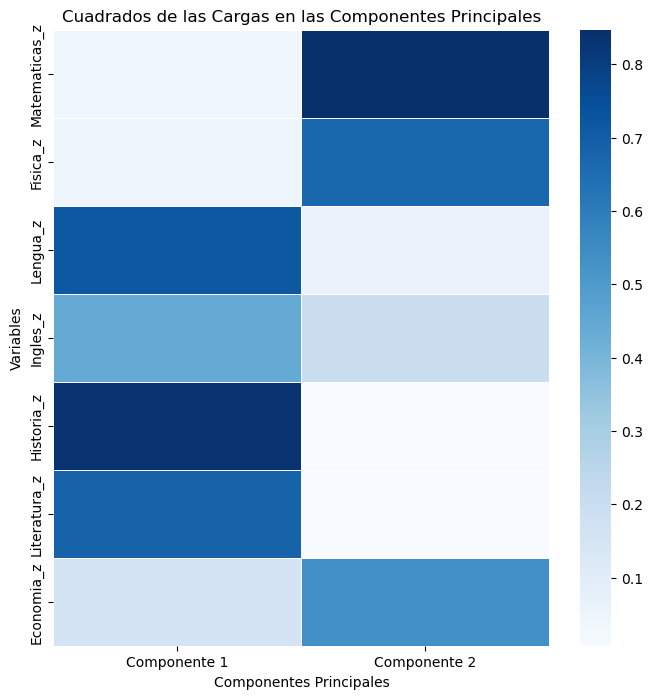

In [29]:
# Contribucion de las componentes a la variabilidad explicada de las variables
def plot_cos2_heatmap(cosenos2):
    """
    Genera un mapa de calor (heatmap) de los cuadrados de las cargas en las Componentes Principales (cosenos al cuadrado).

    Args:
        cosenos2 (pd.DataFrame): DataFrame de los cosenos al cuadrado, donde las filas representan las variables y las columnas las Componentes Principales.

    """
    # Crea una figura de tamaño 8x8 pulgadas para el gráfico
    plt.figure(figsize=(8, 8))

    # Utiliza un mapa de calor (heatmap) para visualizar 'cos2' con un solo color
    sns.heatmap(cosenos2, cmap='Blues', linewidths=0.5, annot=False)

    # Etiqueta los ejes (puedes personalizar los nombres de las filas y columnas si es necesario)
    plt.xlabel('Componentes Principales')
    plt.ylabel('Variables')

    # Establece el título del gráfico
    plt.title('Cuadrados de las Cargas en las Componentes Principales')

    # Muestra el gráfico
    plt.show()


plot_cos2_heatmap(cos2)

Aunque para comparar la variabilidad explicada por las componentes entre el conjunto de variables, es más  visual el siguiente gráfico de barras, donde se representa la suma de los $cos^2$ para cada variable.

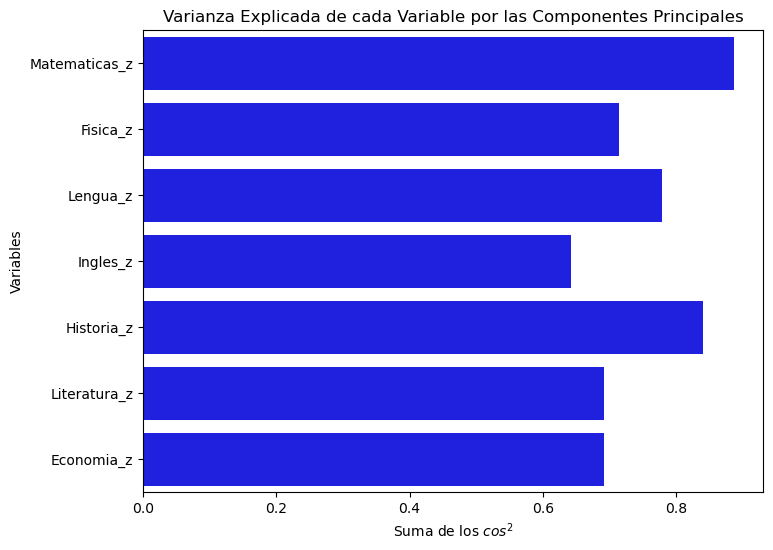

In [30]:
# Cantidad total de variabildiad explicada de una variable por el conjunto de componentes

def plot_cos2_bars(cos2):
    """
    Genera un gráfico de barras para representar la varianza explicada de cada variable utilizando los cuadrados de las cargas (cos^2).

    Args:
        cos2 (pd.DataFrame): DataFrame que contiene los cuadrados de las cargas de las variables en las componentes principales.

    Returns:
        None
    """
    # Crea una figura de tamaño 8x6 pulgadas para el gráfico
    plt.figure(figsize=(8, 6))

    # Crea un gráfico de barras para representar la varianza explicada por cada variable
    sns.barplot(x=cos2.sum(axis=1), y=cos2.index, color="blue")

    # Etiqueta los ejes
    plt.xlabel('Suma de los $cos^2$')
    plt.ylabel('Variables')

    # Establece el título del gráfico
    plt.title('Varianza Explicada de cada Variable por las Componentes Principales')

    # Muestra el gráfico
    plt.show()
    

plot_cos2_bars(cos2)

Con la siguiente función $plot\_corr\_cos$  generamos $\binom{Ncomponentes}{2}$ gráficos diferentes (en este caso particular solo 1), donde se representan las correlaciones entre cada variable y cada par de componentes principales (ejes). El color de cada vector en los gráficos indica el valor de los cosenos al cuadrado.

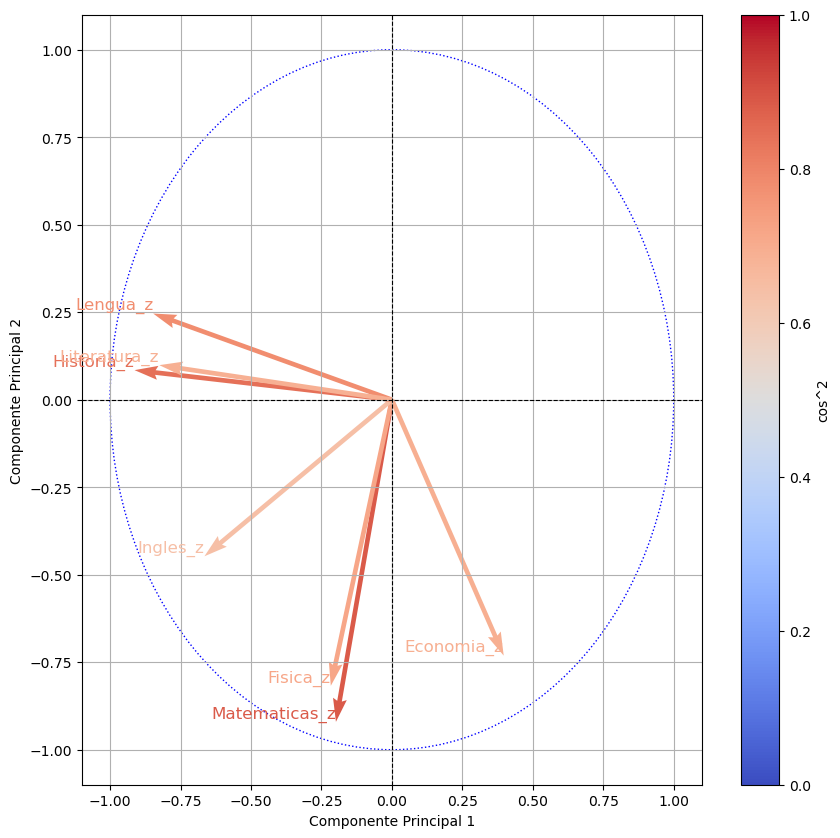

In [31]:

def plot_corr_cos(n_components, correlaciones_datos_con_cp):
    """
    Genera un gráfico en el que se representa un vector por cada variable, usando como ejes las componentes, la orientación
    y la longitud del vector representa la correlación entre cada variable y dos de las componentes. El color representa el
    valor de la suma de los cosenos al cuadrado.
    
    Args:
        n_components (int): Número entero que representa el número de componentes principales seleccionadas.
        correlaciones_datos_con_cp (DataFrame): DataFrame que contiene la matriz de correlaciones entre variables y componentes
    """
    # Definir un mapa de color (cmap) sensible a las diferencias numéricas
    cmap = plt.get_cmap('coolwarm')  # Puedes ajustar el cmap según tus preferencias
    
    for i in range(n_components):
        for j in range(i + 1, n_components):  # Evitar pares duplicados
            # Calcular la suma de los cosenos al cuadrado
            sum_cos2 = correlaciones_datos_con_cp.iloc[:, i] ** 2 + correlaciones_datos_con_cp.iloc[:, j] ** 2
            
            # Crear un nuevo gráfico para cada par de componentes principales
            fig, ax = plt.subplots(figsize=(10, 10))
            
            # Dibujar un círculo de radio 1
            circle = plt.Circle((0, 0), 1, fill=False, color='b', linestyle='dotted')
            ax.add_patch(circle)
            
            # Dibujar vectores para cada variable con colores basados en la suma de los cosenos al cuadrado
            for k, var_name in enumerate(correlaciones_datos_con_cp.index):
                x = correlaciones_datos_con_cp.iloc[k, i]  # Correlación en la primera dimensión
                y = correlaciones_datos_con_cp.iloc[k, j]  # Correlación en la segunda dimensión
                
                # Seleccionar un color de acuerdo a la suma de los cosenos al cuadrado
                color = cmap(sum_cos2.iloc[k])
                
                # Dibujar el vector con el color seleccionado
                ax.quiver(0, 0, x, y, angles='xy', scale_units='xy', scale=1, color=color)
                
                # Agregar el nombre de la variable junto a la flecha con el mismo color
                ax.text(x, y, var_name, color=color, fontsize=12, ha='right', va='bottom')
            
            # Dibujar líneas discontinuas que representen los ejes
            ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
            ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
            
            # Etiquetar los ejes
            ax.set_xlabel(f'Componente Principal {i + 1}')
            ax.set_ylabel(f'Componente Principal {j + 1}')
            
            # Establecer los límites del gráfico
            ax.set_xlim(-1.1, 1.1)
            ax.set_ylim(-1.1, 1.1)
            
            # Agregar un mapa de color (colorbar) y su leyenda
            sm = plt.cm.ScalarMappable(cmap=cmap)
            sm.set_array([])  # Evita errores de escala
            plt.colorbar(sm, ax=ax, orientation='vertical', label='cos^2')  # Agrega la leyenda
            
            # Mostrar el gráfico
            plt.grid()
            plt.show()

plot_corr_cos(fit.n_components, Correlaciones_var_comp)


Como se enunciaba anteriormente, en el gráfico se representa un vector por cada asignatura, siendo los ejes cada una de las componentes seleccionadas, te tal forma que que longitud del vector en cada uno de los ejes representa la correlación en dicha componente, el color del vector es la suma de estas correlaciones al cuadrado ($cos^2$). En este gráfico podemos visualizar como las asignaturas de $'letras'$ están fuertemente relacionadas con la primera componente, y las de $'ciencias'$ con la segunda e Ingles medianamente con ambas. Pero además podemos observar que las variables con el color $rojo$ más intenso son Matemáticas e Historia, lo cual indica que son las variables mejor explicadas por el conjunto de componentes.


Procedemos a continuación a calcular las contribuciones normalizadas de cada variable en la construcción de cada una de las componentes. Representamos los resultados mediante un mapa de calor}donde el valor de las contribuciones dependerá de la intensidad del color azul utilizado.

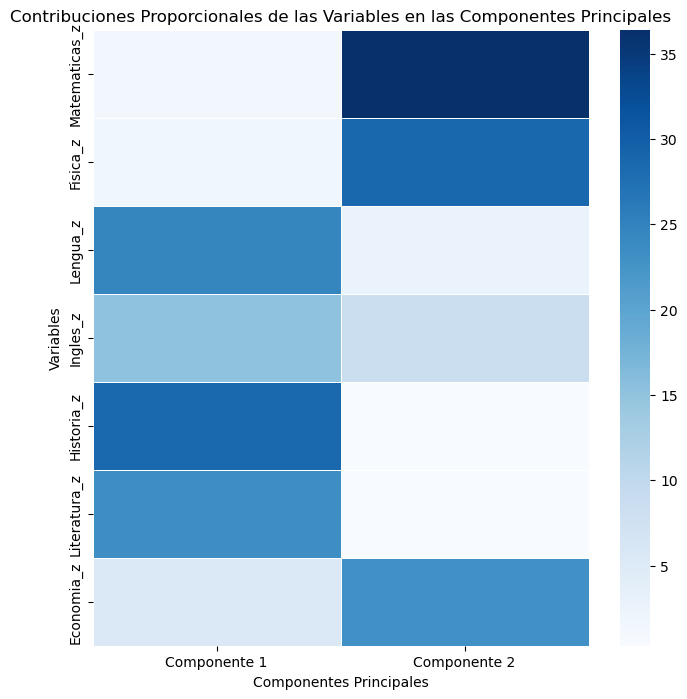

In [32]:
# Contribuciones de cada variable en la construcción de las componentes


def plot_contribuciones_proporcionales(cos2, autovalores, n_components):
    """
    Cacula las contribuciones de cada variable a las componentes principales y
    Genera un gráfico de mapa de calor con los datos
    Args:
        cos2 (DataFrame): DataFrame de los cuadrados de las cargas (cos^2).
        autovalores (array): Array de los autovalores asociados a las componentes principales.
        n_components (int): Número de componentes principales seleccionadas.
    """
    # Calcula las contribuciones multiplicando cos2 por la raíz cuadrada de los autovalores
    contribuciones = cos2 * np.sqrt(autovalores)

    # Inicializa una lista para las sumas de contribuciones
    sumas_contribuciones = []

    # Calcula la suma de las contribuciones para cada componente principal
    for i in range(n_components):
        nombre_componente = f'Componente {i + 1}'
        suma_contribucion = np.sum(contribuciones[nombre_componente])
        sumas_contribuciones.append(suma_contribucion)

    # Calcula las contribuciones proporcionales dividiendo por las sumas de contribuciones
    contribuciones_proporcionales = contribuciones.div(sumas_contribuciones, axis=1) * 100

    # Crea una figura de tamaño 8x8 pulgadas para el gráfico
    plt.figure(figsize=(8, 8))

    # Utiliza un mapa de calor (heatmap) para visualizar las contribuciones proporcionales
    sns.heatmap(contribuciones_proporcionales, cmap='Blues', linewidths=0.5, annot=False)

    # Etiqueta los ejes (puedes personalizar los nombres de las filas y columnas si es necesario)
    plt.xlabel('Componentes Principales')
    plt.ylabel('Variables')

    # Establece el título del gráfico
    plt.title('Contribuciones Proporcionales de las Variables en las Componentes Principales')

    # Muestra el gráfico
    plt.show()
    
    # Devuelve los DataFrames de contribuciones y contribuciones proporcionales
    return contribuciones_proporcionales

contribuciones_proporcionales = plot_contribuciones_proporcionales(cos2,autovalores,fit.n_components)


En este gráfico volvemos a corroborar lo ya observado anteriormente, las variables de $letras$, participan fuertemente en la construcción de la primera Componente, las de $ciencias$ en la segunda, e ingles medianamente en ambas.


### Coordenadas en los nuevos ejes
A continuación vamos a representar a los individuos utilizando como ejes cada par de Componentes principales (en este ejemplo solo 1).



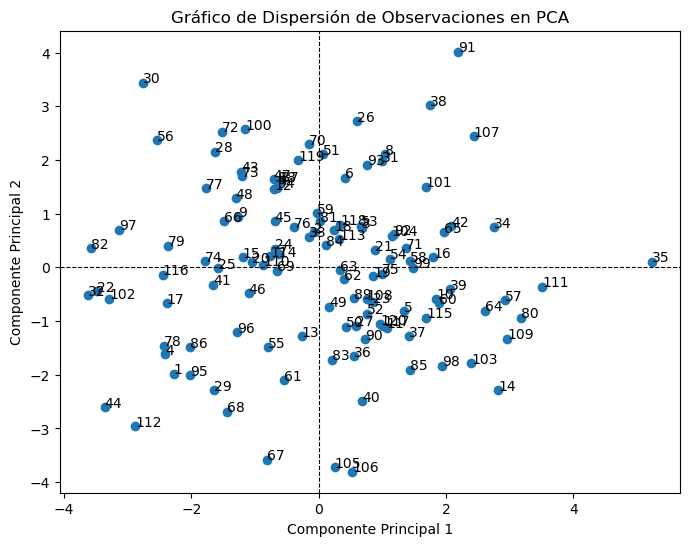

In [33]:
# Nube de puntos de las observaciones en las componentes = ejes

def plot_pca_scatter(pca, datos_estandarizados, n_components):
    """
    Genera gráficos de dispersión de observaciones en pares de componentes principales seleccionados.

    Args:
        pca (PCA): Objeto PCA previamente ajustado.
        datos_estandarizados (pd.DataFrame): DataFrame de datos estandarizados.
        n_components (int): Número de componentes principales seleccionadas.
    """
    # Representamos las observaciones en cada par de componentes seleccionadas
    componentes_principales = pca.transform(datos_estandarizados)
    
    for i in range(n_components):
        for j in range(i + 1, n_components):  # Evitar pares duplicados
            # Calcular la suma de los valores al cuadrado para cada variable
            # Crea un gráfico de dispersión de las observaciones en las dos primeras componentes principales
            plt.figure(figsize=(8, 6))  # Ajusta el tamaño de la figura si es necesario
            plt.scatter(componentes_principales[:, i], componentes_principales[:, j])
            
            # Añade etiquetas a las observaciones
            etiquetas_de_observaciones = list(datos_estandarizados.index)
    
            for k, label in enumerate(etiquetas_de_observaciones):
                plt.annotate(label, (componentes_principales[k, i], componentes_principales[k, j]))
            
            # Dibujar líneas discontinuas que representen los ejes
            plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
            plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
            
            # Etiquetar los ejes
            plt.xlabel(f'Componente Principal {i + 1}')
            plt.ylabel(f'Componente Principal {j + 1}')
            
            # Establece el título del gráfico
            plt.title('Gráfico de Dispersión de Observaciones en PCA')
            
            plt.show()
            
plot_pca_scatter(pca, notas_estandarizadas, fit.n_components)


Podemos modificar el código anterior para que el gráfico nos inlcuya un vector que represente para cada una de las variables la correlación escalada con las componentes (ejes) del gráfico. 

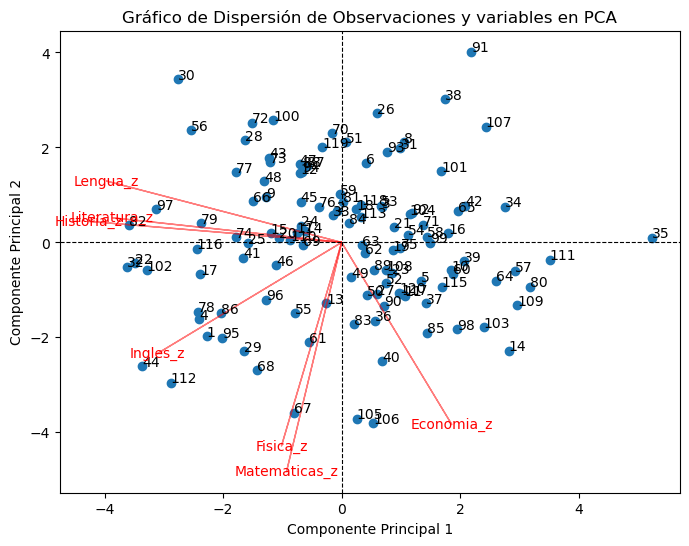

In [34]:
# Nube de puntos de las observaciones en las componentes = ejes y correlaciones entre variables y componentes
def plot_pca_scatter_with_vectors(pca, datos_estandarizados, n_components, components_):
    """
    Genera gráficos de dispersión de observaciones en pares de componentes principales seleccionados
    con vectores de las correlaciones escaladas entre variables y componentes

    Args:
        pca (PCA): Objeto PCA previamente ajustado.
        datos_estandarizados (pd.DataFrame): DataFrame de datos estandarizados.
        n_components (int): Número de componentes principales seleccionadas.
        components_: Array con las componentes.
    """
    # Representamos las observaciones en cada par de componentes seleccionadas
    componentes_principales = pca.transform(datos_estandarizados)
    
    for i in range(n_components):
        for j in range(i + 1, n_components):  # Evitar pares duplicados
            # Calcular la suma de los valores al cuadrado para cada variable
            # Crea un gráfico de dispersión de las observaciones en las dos primeras componentes principales
            plt.figure(figsize=(8, 6))  # Ajusta el tamaño de la figura si es necesario
            plt.scatter(componentes_principales[:, i], componentes_principales[:, j])
            
            # Añade etiquetas a las observaciones
            etiquetas_de_observaciones = list(datos_estandarizados.index)
    
            for k, label in enumerate(etiquetas_de_observaciones):
                plt.annotate(label, (componentes_principales[k, i], componentes_principales[k, j]))
            
            # Dibujar líneas discontinuas que representen los ejes
            plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
            plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
            
            # Etiquetar los ejes
            plt.xlabel(f'Componente Principal {i + 1}')
            plt.ylabel(f'Componente Principal {j + 1}')
            
            # Establece el título del gráfico
            plt.title('Gráfico de Dispersión de Observaciones y variables en PCA')
            
            
            # Añadimos vectores que representen las correlaciones escaladas entre variables y componentes
            fit = pca.fit(datos_estandarizados)
            coeff = np.transpose(fit.components_)
            scaled_coeff = 8 * coeff  #8 = escalado utilizado, ajustar en función del ejemplo
            for var_idx in range(scaled_coeff.shape[0]):
                plt.arrow(0, 0, scaled_coeff[var_idx, i], scaled_coeff[var_idx, j], color='red', alpha=0.5)
                plt.text(scaled_coeff[var_idx, i], scaled_coeff[var_idx, j],
                     notas_estandarizadas.columns[var_idx], color='red', ha='center', va='center')
            
            plt.show()
            
plot_pca_scatter_with_vectors(pca, notas_estandarizadas, fit.n_components, fit.components_)


Observemos, por ejemplo, que los alumnos 67 y 106 deben tener buenas notas en las asignaturas de $ciencias$ mientras que en letras tienen notas sobre la media (su coordenada en la $CP_1$ es próxima cero). Destacamos también al alumno 35, que debe tener muy malas notas en las signaturas de  $letras$ y en torno a la media en las de $ciencias$.

In [35]:
estadisticos.loc[:, 'Media']

Matematicas    5.302194
Fisica         4.631731
Lengua         5.971550
Ingles         6.806254
Historia       6.354733
Literatura     6.614774
Economia       5.120498
Name: Media, dtype: float64

In [36]:
notas.iloc[34]

Matematicas    4.195230
Fisica         4.836945
Lengua         3.125414
Ingles         3.271631
Historia       2.326892
Literatura     2.459939
Economia       5.998179
Name: 35, dtype: float64

In [37]:
notas.iloc[105]

Matematicas    8.512903
Fisica         7.678998
Lengua         5.286330
Ingles         7.322226
Historia       5.851546
Literatura     6.167387
Economia       8.779209
Name: 106, dtype: float64

## Elementos suplementarios



La inclusión de individuos y variables suplementarias en el PCA nos permite evaluar cómo se sitúan en relación con la estructura existente de las componentes principales y cómo contribuyen a la variabilidad general. Esto es esencial para mantener nuestro análisis actualizado y relevante en entornos en constante cambio.


Para aplicar esto a nuestro ejemplo particular vamos a utilizar los datos de 4 nuevos alumnos, los cuales están en el archivo 'NOTAS\_S.xlsx'

In [38]:
# Observaciones suplementarias

# Cargar un archivo Excel llamado 'notas.xlsx' en un DataFrame llamado notas.
notas_S = pd.read_excel('notas_S.xlsx') 
notas_S

,Alumno,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia,EXTRA_ESC
0,121,6.8,5.7,5.6,7.6,8.3,7.7,5.8,Deporte
1,122,7.5,6.5,4.5,6.5,3.6,4.8,7.3,Música
2,123,4.7,3.2,3.5,5.4,4.6,5.6,5.3,Deporte
3,124,8.5,7.8,6.7,8.9,6.7,8.8,9.5,Musi-Dep


In [39]:
# Establecer la columna 'Alumno' como índice del DataFrame notas y eliminarla.
notas_S = notas_S.set_index('Alumno', drop=True)
notas_S



,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia,EXTRA_ESC
Alumno,,,,,,,,
121,6.8,5.7,5.6,7.6,8.3,7.7,5.8,Deporte
122,7.5,6.5,4.5,6.5,3.6,4.8,7.3,Música
123,4.7,3.2,3.5,5.4,4.6,5.6,5.3,Deporte
124,8.5,7.8,6.7,8.9,6.7,8.8,9.5,Musi-Dep


In [40]:
# Guarda la variable el indice y 'EXTRA_ESC' en un dataframe
extra_S = notas_S.iloc[:, [7]]
extra_S


,EXTRA_ESC
Alumno,
121,Deporte
122,Música
123,Deporte
124,Musi-Dep


In [41]:
# Elimina la variable 'EXTRA_ESC' del DataFrame 'notas'.
notas_S = notas_S.drop(notas_S.columns[7], axis=1)
notas_S

,Matematicas,Fisica,Lengua,Ingles,Historia,Literatura,Economia
Alumno,,,,,,,
121,6.8,5.7,5.6,7.6,8.3,7.7,5.8
122,7.5,6.5,4.5,6.5,3.6,4.8,7.3
123,4.7,3.2,3.5,5.4,4.6,5.6,5.3
124,8.5,7.8,6.7,8.9,6.7,8.8,9.5


### Observaciones Suplementarias
Lo que debemos hacer al recibir usuarios nuevos es lo siguiente, en primer lugar, estandarizar los datos, con la media y desviación tipica de los datos originales. Posteriormente, calcular sus coordenadas en las componentes creadas en el PCA.

In [42]:

# Calcular la media y la desviación estándar de 'notas'
media_notas = notas.mean()
desviacion_estandar_notas = notas.std()

# Estandarizar 'notas_S' utilizando la media y la desviación estándar de 'notas'
notas_S_estandarizadas = pd.DataFrame(((notas_S - media_notas) / desviacion_estandar_notas))

notas_S_estandarizadas.columns = ['{}_z'.format(variable) for variable in variables]

# Agregar las observaciones estandarizadas a 'notas'
notas_sup = pd.concat([notas_estandarizadas, notas_S_estandarizadas])

# Calcular las componentes principales para el conjunto de datos combinado
componentes_principales_sup = pca.transform(notas_sup)

# Calcular las componentes principales para el conjunto de datos combinado
# y renombra las componentes
resultados_pca_sup = pd.DataFrame(fit.transform(notas_sup), 
                              columns=['Componente {}'.format(i) for i in range(1, fit.n_components_+1)],
                              index=notas_sup.index)


resultados_pca_sup

,Componente 1,Componente 2
Alumno,,
1,-2.275246,-1.981018
2,-0.074596,0.655838
3,0.684463,0.740888
4,-2.408402,-1.619371
5,1.339605,-0.813157
...,...,...
120,0.968907,-1.060622
121,-1.292759,-1.288613
122,2.335024,-2.573652


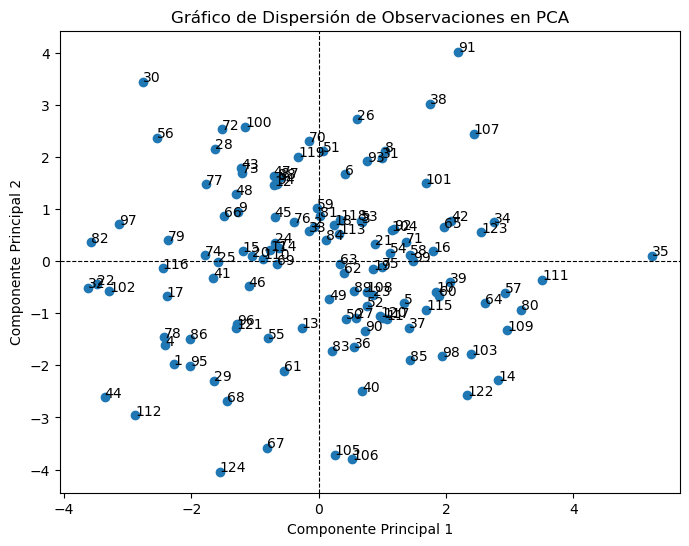

In [43]:
# Representacion observaciones + suplementarios
plot_pca_scatter(pca, notas_sup, fit.n_components)

## Variables Suplementarias

Por último vamos  vamos a considerar la posibilidad de añadir una nueva variable categórica al análisis, como sabemos, las variables categóricas no peuden pertenecer al PCA, pero, ¿Como se relacionaría con dicho analisis?

Cuando incorporamos una variable categórica a un PCA previamente realizado, estamos enriqueciendo nuestra comprensión de los datos al considerar la influencia de categorías adicionales en la estructura de los datos. En este contexto, representar los centroides de estas categorías en los nuevos ejes de las componentes principales se convierte en una estrategia esencial. Los centroides actúan como puntos de referencia que resumen la tendencia central de cada categoría en el espacio de las CP. Este enfoque nos permite visualizar cómo las distintas categorías se relacionan entre sí y con las CP, lo que puede revelar patrones y relaciones más sutiles en los datos que antes no eran evidentes. En esencia, al considerar variables categóricas y representar sus centroides en el PCA, estamos agregando una dimensión adicional a nuestra comprensión de la estructura subyacente de los datos.

Volviendo a nuestro ejemplo, vamos a retomar la variable categórica $EXTRA\_ESC$ para ver si hay algún patrón visible entre la actividad extraescolar de los alumnos y las CP. 

In [44]:


# Variable suplementaria
# Añadimos la variable categórica "EXTRA_ESC" en los datos
notas_componentes_sup= pd.concat([notas_sup, resultados_pca_sup], axis=1)  
extra_sup = pd.concat([extra, extra_S], axis=0)
notas_componentes_sup_extra= pd.concat([notas_componentes_sup,
                                               extra_sup], axis=1)  
notas_componentes_sup_extra

,Matematicas_z,Fisica_z,Lengua_z,Ingles_z,Historia_z,Literatura_z,Economia_z,Componente 1,Componente 2,EXTRA_ESC
Alumno,,,,,,,,,,
1,1.984788,1.288100,0.412892,0.423952,2.130991,0.989359,0.454951,-2.275246,-1.981018,Musi-Dep
2,0.046385,-0.462778,0.053811,-0.501785,-0.119002,0.489940,-0.531895,-0.074596,0.655838,Deporte
3,-0.627619,-1.086494,0.357885,-0.381030,-0.699891,0.091006,0.743655,0.684463,0.740888,Deporte
4,1.595663,0.782447,1.611981,0.873680,0.675615,1.678652,0.809081,-2.408402,-1.619371,Musi-Dep
5,0.057113,0.747611,-0.598737,-0.767947,-0.665394,-0.580099,0.901758,1.339605,-0.813157,Deporte
...,...,...,...,...,...,...,...,...,...,...
120,-0.062911,0.347714,-0.939336,1.519755,-1.033581,-1.005639,0.401920,0.968907,-1.060622,Deporte
121,1.019061,0.704962,-0.291450,0.546963,1.416568,0.753325,0.450680,-1.292759,-1.288613,Deporte
122,1.495320,1.232891,-1.154308,-0.206105,-2.006030,-1.252012,1.445555,2.335024,-2.573652,Música


Representamos los centroides en las componentes creadas

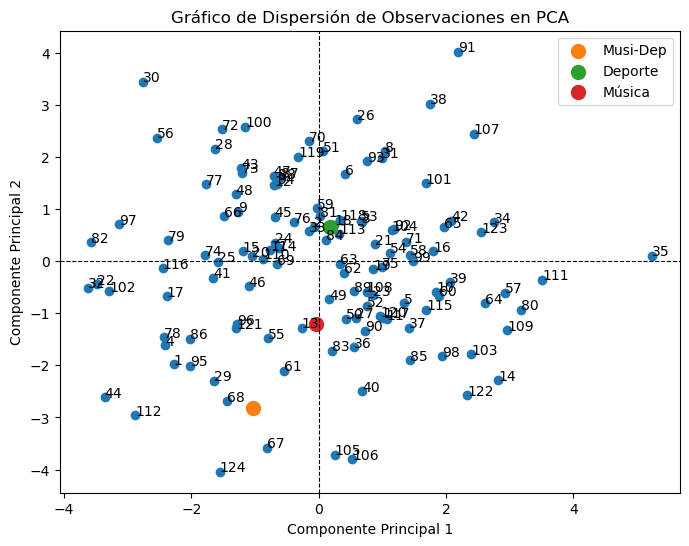

In [99]:
def plot_pca_scatter_with_categories(datos_componentes_sup_var, componentes_principales_sup, n_components, var_categ):
    """
    Genera gráficos de dispersión de observaciones en pares de componentes principales seleccionados con categorías.

    Args:
        datos_componentes_sup_var (pd.DataFrame): DataFrame que contiene las categorías.
        componentes_principales_sup (np.ndarray): Matriz de componentes principales.
        n_components (int): Número de componentes principales seleccionadas.
        var_categ (str): Nombre de la variable introducida
    """
    # Obtener las categorías únicas
    categorias = datos_componentes_sup_var[var_categ].unique()

    # Iterar sobre todos los posibles pares de componentes principales
    for i in range(n_components):
        for j in range(i + 1, n_components):
            # Crear un gráfico de dispersión de las observaciones en las dos primeras componentes principales
            plt.figure(figsize=(8, 6))
            plt.scatter(componentes_principales_sup[:, i], componentes_principales_sup[:, j])

            for categoria in categorias:
                # Filtrar las observaciones por categoría
                observaciones_categoria = componentes_principales_sup[datos_componentes_sup_var[var_categ] == categoria]
                # Calcular el centroide de la categoría
                centroide = np.mean(observaciones_categoria, axis=0)
                plt.scatter(centroide[i], centroide[j], label=categoria, s=100, marker='o')

            # Añadir etiquetas a las observaciones
            etiquetas_de_observaciones = list(datos_componentes_sup_var.index)

            for k, label in enumerate(etiquetas_de_observaciones):
                plt.annotate(label, (componentes_principales_sup[k, i], componentes_principales_sup[k, j]))

            # Dibujar líneas discontinuas que representen los ejes
            plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
            plt.axvline(0, color='black', linestyle='--', linewidth=0.8)

            # Etiquetar los ejes
            plt.xlabel(f'Componente Principal {i + 1}')
            plt.ylabel(f'Componente Principal {j + 1}')

            # Establecer el título del gráfico
            plt.title('Gráfico de Dispersión de Observaciones en PCA')

            # Mostrar la leyenda para las categorías
            plt.legend()
            plt.show()
plot_pca_scatter_with_categories(notas_componentes_sup_extra, componentes_principales_sup, fit.n_components, 'EXTRA_ESC')
